In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv("../data/amazon_reviews_preprocessed.csv")

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

df.head()

Dataset shape: (20000, 4)
Columns: ['review_text', 'label', 'sentiment', 'cleaned_text']


,review_text,label,sentiment,cleaned_text
0,"Good diapers, some blowouts I like these diape...",1,GOOD,good diapers some blowouts i like these diaper...
1,Broke within a month Even though I always peel...,0,BAD,broke within a month even though i always peel...
2,"Manipulative, offensive, innacurate As others ...",0,BAD,manipulative offensive innacurate as others sa...
3,The Truman Show for Dummies A watered-down Tru...,0,BAD,the truman show for dummies a watered down tru...
4,Straight Fire! Holy Culture was my introductio...,1,GOOD,straight fire holy culture was my introduction...


In [3]:
print("Missing cleaned reviews:", df["cleaned_text"].isna().sum())
print("Missing labels:", df["label"].isna().sum())
print("\nLabel distribution:")
print(df["label"].value_counts(dropna=False))

print("\nUnique labels:", sorted(df["label"].dropna().unique()))

Missing cleaned reviews: 0
Missing labels: 0

Label distribution:
label
1    10000
0    10000
Name: count, dtype: int64

Unique labels: [np.int64(0), np.int64(1)]


In [4]:
from sklearn.model_selection import train_test_split

X = df["cleaned_text"]
y = df["label"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

Training samples: 14000
Validation samples: 3000
Testing samples: 3000


In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=30000,
    min_df=2,
    max_df=0.95,
    sublinear_tf=True,
    dtype=np.float32
)

X_train_tfidf = vectorizer.fit_transform(X_train)

X_val_tfidf = vectorizer.transform(X_val)
X_test_tfidf = vectorizer.transform(X_test)

print("Training matrix:", X_train_tfidf.shape)
print("Validation matrix:", X_val_tfidf.shape)
print("Testing matrix:", X_test_tfidf.shape)
print("Vocabulary size:", len(vectorizer.vocabulary_))

Training matrix: (14000, 30000)
Validation matrix: (3000, 30000)
Testing matrix: (3000, 30000)
Vocabulary size: 30000


In [6]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_model.fit(X_train_tfidf, y_train)

print("Logistic Regression training completed.")

Logistic Regression training completed.


In [8]:
from sklearn.naive_bayes import MultinomialNB

nb_model = MultinomialNB(alpha=1.0)

nb_model.fit(X_train_tfidf, y_train)

print("Multinomial Naive Bayes training completed.")

Multinomial Naive Bayes training completed.


In [9]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

models = {
    "Logistic Regression": lr_model,
    "Multinomial Naive Bayes": nb_model
}

results = []

for name, model in models.items():
    y_pred = model.predict(X_val_tfidf)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision (Macro)": precision_score(
            y_val, y_pred, average="macro", zero_division=0
        ),
        "Recall (Macro)": recall_score(
            y_val, y_pred, average="macro", zero_division=0
        ),
        "F1 (Macro)": f1_score(
            y_val, y_pred, average="macro", zero_division=0
        )
    })

results_df = pd.DataFrame(results).sort_values(
    "F1 (Macro)", ascending=False
)

results_df

,Model,Accuracy,Precision (Macro),Recall (Macro),F1 (Macro)
0,Logistic Regression,0.884000,0.884068,0.884000,0.883995
1,Multinomial Naive Bayes,0.870667,0.870746,0.870667,0.870660



Logistic Regression
Confusion Matrix:
[[1336  164]
 [ 184 1316]]


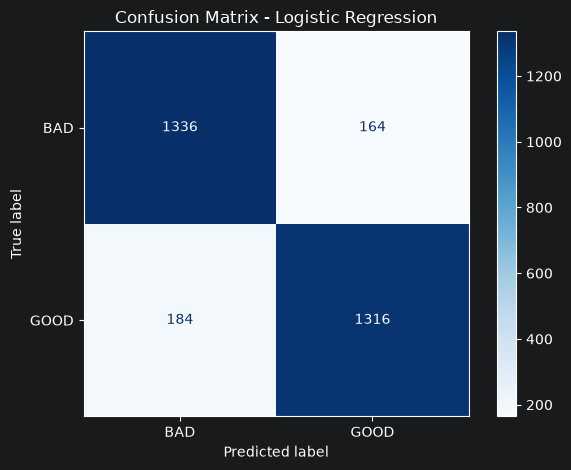


Multinomial Naive Bayes
Confusion Matrix:
[[1317  183]
 [ 205 1295]]


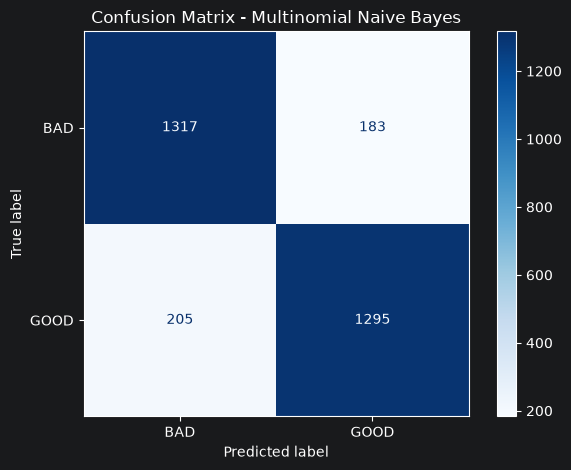

In [11]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

for name, model in models.items():
    y_pred = model.predict(X_val_tfidf)

    cm = confusion_matrix(y_val, y_pred, labels=[0, 1])

    print(f"\n{name}")
    print("Confusion Matrix:")
    print(cm)

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["BAD", "GOOD"]
    ).plot(cmap="Blues", values_format="d")

    plt.title(f"Confusion Matrix - {name}")
    plt.tight_layout()
    plt.show()